*House Price Analysis and Prediction*

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
uploaded = files.upload()
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)
print("Dataset uploaded successfully!")
print("Dataset Shape:", df.shape)
display(df.head())

Saving Housing.csv to Housing.csv
Dataset uploaded successfully!
Dataset Shape: (545, 13)


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [ ]:
# Display dataset information
print("Dataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Remove rows without a target price
df = df.dropna(subset=["price"]).copy()

# Convert price into numeric format
df["price"] = pd.to_numeric(df["price"], errors="coerce")

# Remove invalid or missing prices
df = df.dropna(subset=["price"])
df = df[df["price"] > 0].copy()

print("\nCleaned Dataset Shape:", df.shape)
print("Data cleaning completed!")

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB

Missing Values:
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainro

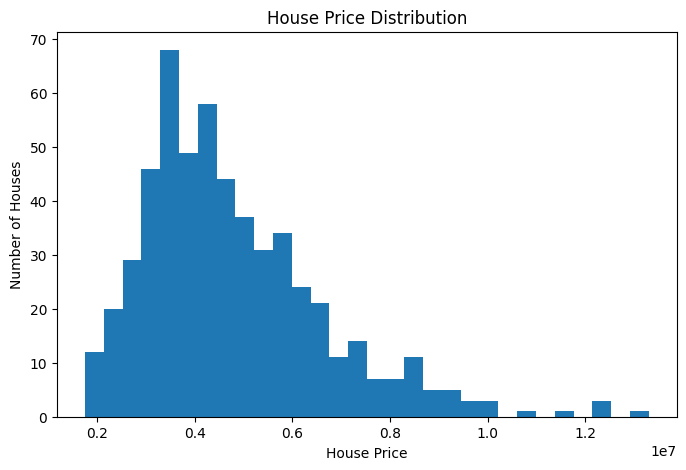

In [ ]:
# House price distribution
plt.figure(figsize=(8, 5))
plt.hist(df["price"], bins=30)
plt.title("House Price Distribution")
plt.xlabel("House Price")
plt.ylabel("Number of Houses")
plt.show()

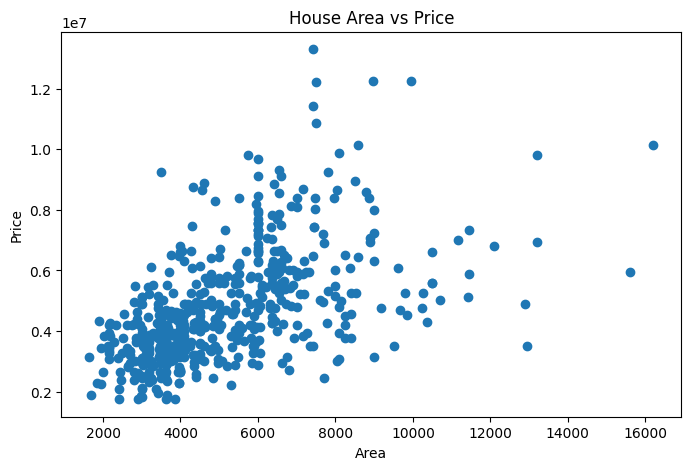

In [ ]:
# Area versus price
plt.figure(figsize=(8, 5))
plt.scatter(df["area"], df["price"])
plt.title("House Area vs Price")
plt.xlabel("Area")
plt.ylabel("Price")
plt.show()

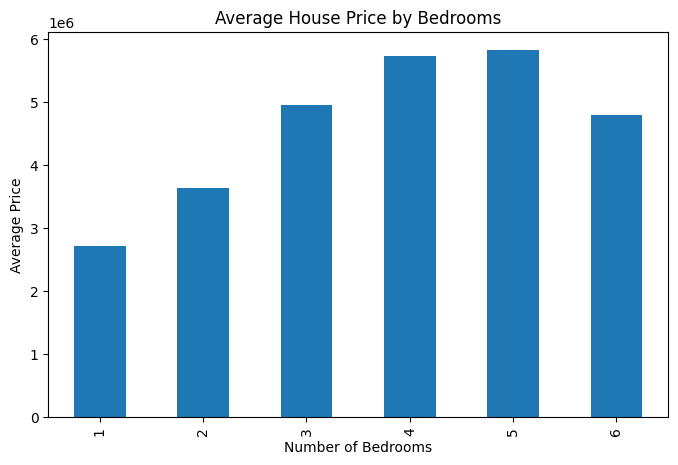

In [ ]:
# Average price by number of bedrooms
bedroom_prices = df.groupby("bedrooms")["price"].mean()

bedroom_prices.plot(kind="bar", figsize=(8, 5))
plt.title("Average House Price by Bedrooms")
plt.xlabel("Number of Bedrooms")
plt.ylabel("Average Price")
plt.show()

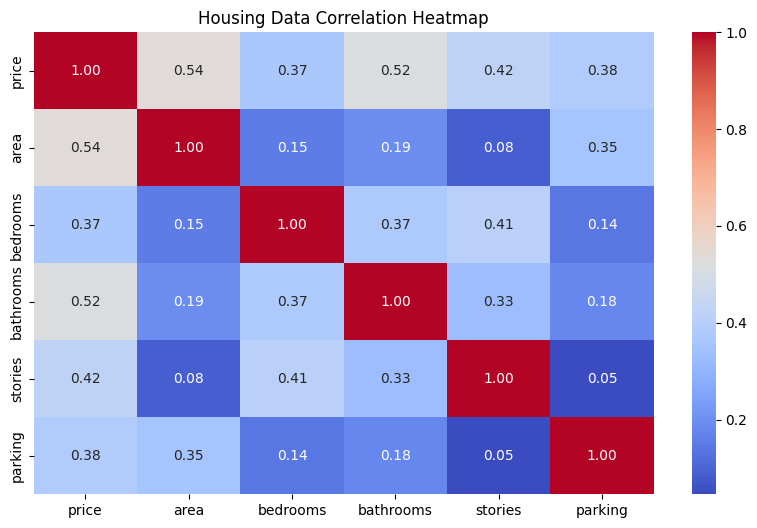

In [ ]:
# Correlation heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Housing Data Correlation Heatmap")
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Separate input features and target
X = df.drop("price", axis=1)
y = df["price"]

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Numerical data processing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical data processing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Split data into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Data preparation completed!")

Training records: 436
Testing records: 109
Data preparation completed!


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42
    )
}

results = {}
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results[name] = {
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    }

    trained_models[name] = pipeline

    print("\nModel:", name)
    print("MAE:", round(mae, 2))
    print("RMSE:", round(rmse, 2))
    print("R2 Score:", round(r2, 4))

print("\nModel training completed!")


Model: Linear Regression
MAE: 970043.4
RMSE: 1324506.96
R2 Score: 0.6529

Model: Random Forest
MAE: 1015097.18
RMSE: 1398658.02
R2 Score: 0.613

Model training completed!


In [ ]:
results_df = pd.DataFrame(results).T

print("Model Comparison:")
display(results_df)

# Select the model with the lowest MAE
best_model_name = results_df["MAE"].idxmin()
best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

Model Comparison:


,MAE,RMSE,R2 Score
Linear Regression,9.700434e+05,1.324507e+06,0.652924
Random Forest,1.015097e+06,1.398658e+06,0.612975


Best Model: Linear Regression


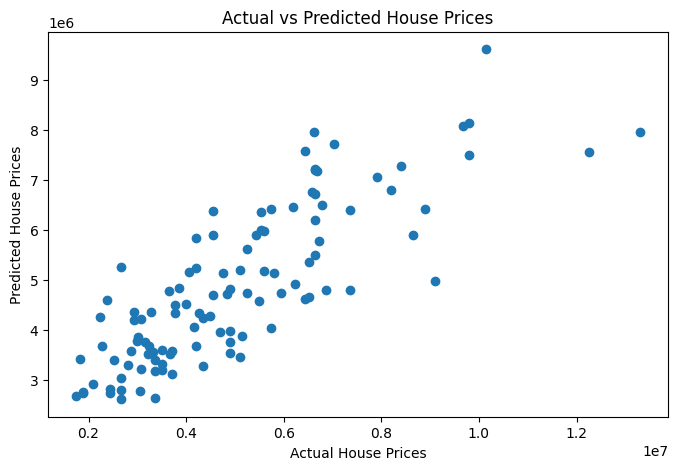

In [ ]:
predictions = best_model.predict(X_test)

plt.figure(figsize=(8, 5))

plt.scatter(y_test, predictions)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices")

plt.show()

In [ ]:
new_house = pd.DataFrame([{
    "area": 1200,
    "bedrooms": 2,
    "bathrooms": 2,
    "stories": 2,
    "mainroad": "yes",
    "guestroom": "no",
    "basement": "no",
    "hotwaterheating": "no",
    "airconditioning": "yes",
    "parking": 1,
    "prefarea": "yes",
    "furnishingstatus": "semi-furnished"
}])

predicted_price = best_model.predict(new_house)[0]

print("House Details:")
display(new_house)

print("Predicted House Price:", round(predicted_price, 2))

House Details:


,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,1200,2,2,2,yes,no,no,no,yes,1,yes,semi-furnished


Predicted House Price: 5587792.43


In [ ]:
import joblib

joblib.dump(best_model, "house_price_model.pkl")

print("Model saved successfully!")

from google.colab import files
files.download("house_price_model.pkl")

Model saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Conclusion:**

The House Price Analysis and Prediction project uses Python and Machine Learning to estimate house prices based on different housing features. The dataset was cleaned and analysed using graphs and visualizations. Linear Regression and Random Forest algorithms were trained and evaluated using MAE, RMSE and R² score. The project also demonstrates house price predictions using sample inputs. This project helped me understand data analysis, data preprocessing, regression models and machine learning predictions.